In [11]:
import pandas as pd
import numpy as np
from sklearn.decomposition import FactorAnalysis
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, r2_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import matplotlib.pyplot as plt

## Prepare Data

In [12]:
df = pd.read_csv("../dataset/preprocessed_data_minmax_scaled.csv")

# Select target columns for factor analysis
cols_to_analyze = ['CO', 'Ozone', 'PM10', 'PM25', 'NO2']
X = df[cols_to_analyze].copy()

# Create AQI categories
# 0-50 = Good, 50-100 = Moderate, 100+ = Unhealthy
df['AQI_Category'] = pd.cut(
    df['Overall AQI Value'],
    bins=[0, 50, 100, np.inf],
    labels=['Good', 'Moderate', 'Unhealthy']
)
y = df['AQI_Category']

# Encode category labels to numerical values
le = LabelEncoder()
y_encoded = le.fit_transform(y)

## Factor Analysis

In [13]:
k = 4     # Set number of factors to extract
#Setup FA model
fa = FactorAnalysis(n_components=k, random_state=42)
factor_scores = fa.fit_transform(X)

# Extract and display factor loadings
loadings = pd.DataFrame(
    fa.components_.T,
    index=cols_to_analyze,
    columns=[f"Factor{i+1}" for i in range(k)]
)
print("===== Factor Loadings =====")
print(loadings.round(3))

===== Factor Loadings =====
       Factor1  Factor2  Factor3  Factor4
CO       0.045   -0.026    0.000   -0.001
Ozone    0.034    0.066   -0.012   -0.012
PM10     0.056    0.024   -0.006    0.007
PM25     0.058    0.006    0.007   -0.001
NO2      0.090   -0.067   -0.084   -0.003


In [14]:
#Interpret the factors by identifying which variables contribute most to each factor
for i in range(k):
    top_vars = loadings.iloc[:, i].abs().sort_values(ascending=False).index[:2]
    print(f"Factor {i+1} is primarily represented by:", list(top_vars))

Factor 1 is primarily represented by: ['NO2', 'PM25']
Factor 2 is primarily represented by: ['NO2', 'Ozone']
Factor 3 is primarily represented by: ['NO2', 'Ozone']
Factor 4 is primarily represented by: ['Ozone', 'PM10']


## Train Non-Linear SVM Classifier

In [15]:
# Split the factor scores
X_train, X_test, y_train, y_test = train_test_split(
    factor_scores, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# SVM classifier with 'RBF', capture non-linear relationships 
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

## Train Logistic Regression (Baseline)

In [16]:
logreg = LogisticRegression(max_iter=500)
logreg.fit(X_train, y_train)
y_pred_lr = logreg.predict(X_test)

## Models Performance Metrics

In [17]:
def model_performance(name, y_pred_one):
    # Calculate classification metrics
    acc = accuracy_score(y_test, y_pred_one)
    prec = precision_score(y_test, y_pred_one, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred_one, average='weighted')
    f1 = f1_score(y_test, y_pred_one, average='weighted')
    mse = mean_squared_error(y_test, y_pred_one)
    r2 = r2_score(y_test, y_pred_one)
    #classification metrics
    print(f"\n===== Classification Metrics ({name}) =====")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"R²: {r2:.4f}")
    #classification report
    print("\n===== Classification Report =====")
    print(classification_report(y_test, y_pred_one, target_names=le.classes_))
    #Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_one)
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


===== Classification Metrics (SVM) =====
Accuracy: 0.9481
Precision: 0.9485
Recall: 0.9481
F1-score: 0.9480
MSE: 0.0519
R²: 0.8430

===== Classification Report =====
              precision    recall  f1-score   support

        Good       0.94      0.97      0.95       185
    Moderate       0.96      0.93      0.94       166
   Unhealthy       1.00      0.93      0.97        15

    accuracy                           0.95       366
   macro avg       0.96      0.94      0.95       366
weighted avg       0.95      0.95      0.95       366



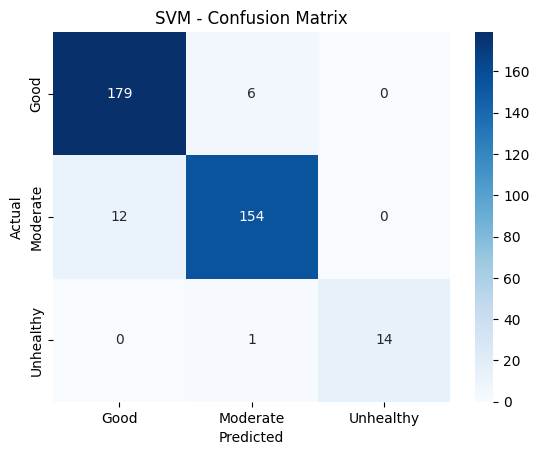

In [18]:
model_performance("SVM", y_pred)


===== Classification Metrics (Logistic Regression) =====
Accuracy: 0.9208
Precision: 0.9223
Recall: 0.9208
F1-score: 0.9206
MSE: 0.0792
R²: 0.7604

===== Classification Report =====
              precision    recall  f1-score   support

        Good       0.90      0.96      0.93       185
    Moderate       0.94      0.88      0.91       166
   Unhealthy       1.00      0.93      0.97        15

    accuracy                           0.92       366
   macro avg       0.95      0.92      0.93       366
weighted avg       0.92      0.92      0.92       366



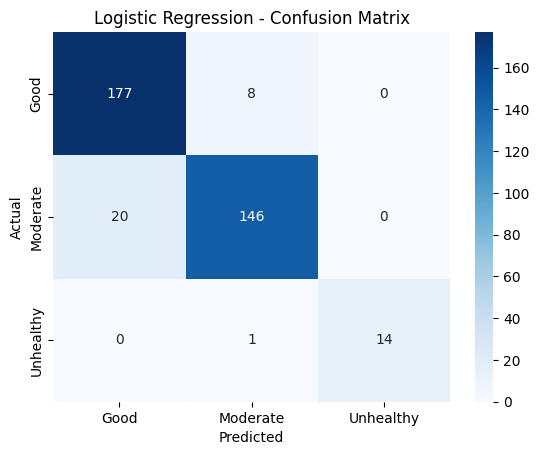

In [19]:
model_performance("Logistic Regression", y_pred_lr)

## Classifiction Projection

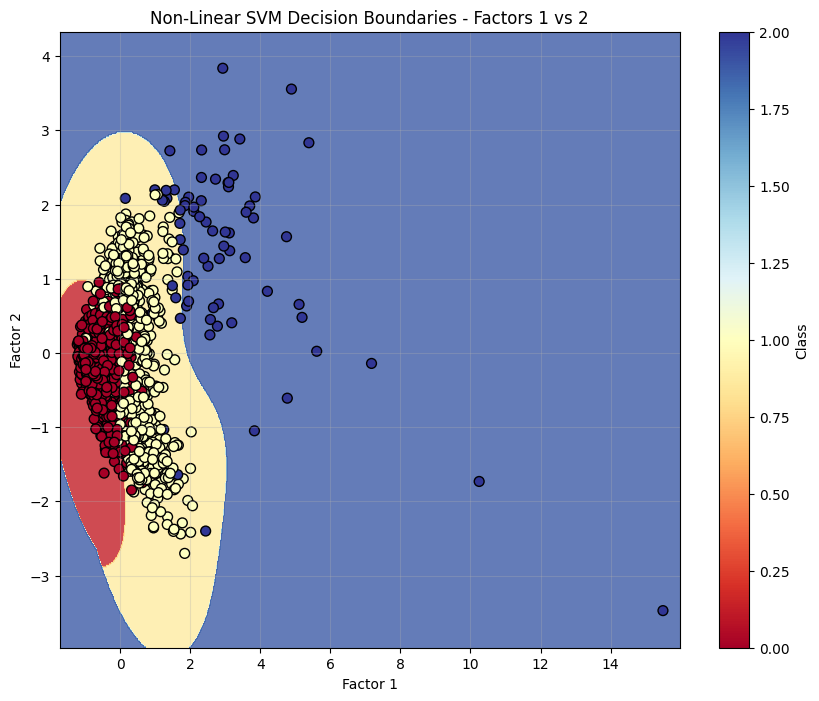

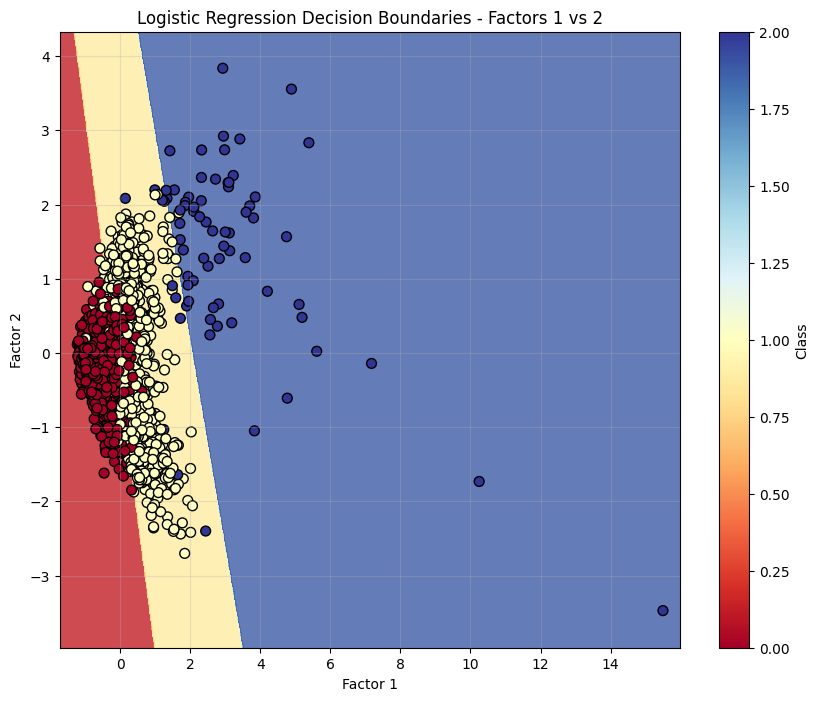

In [20]:
def plot_decision_boundaries(factor1, factor2, model, title):
    plt.figure(figsize=(10, 8))
    
    # Create mesh grid
    h = 0.02
    x_min, x_max = factor_scores[:, factor1].min() - 0.5, factor_scores[:, factor1].max() + 0.5
    y_min, y_max = factor_scores[:, factor2].min() - 0.5, factor_scores[:, factor2].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    
    # Predict on mesh grid
    mesh_points = np.c_[xx.ravel(), yy.ravel()]
    # Add zeros for other factors to maintain dimensionality
    full_mesh = np.zeros((mesh_points.shape[0], k))
    full_mesh[:, factor1] = mesh_points[:, 0]
    full_mesh[:, factor2] = mesh_points[:, 1]
    
    Z = model.predict(full_mesh)
    Z = Z.reshape(xx.shape)
    
    # Plot decision boundary
    plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)
    
    # Plot data points
    scatter = plt.scatter(factor_scores[:, factor1], factor_scores[:, factor2], 
                         c=y_encoded, cmap=plt.cm.RdYlBu, edgecolors='black', s=50)
    
    plt.xlabel(f'Factor {factor1+1}')
    plt.ylabel(f'Factor {factor2+1}')
    plt.title(title)
    plt.colorbar(scatter, label='Class')
    plt.grid(alpha=0.3)
    plt.show()

# Plot decision boundaries for first two factors
plot_decision_boundaries(0, 1, svm_model, "Non-Linear SVM Decision Boundaries - Factors 1 vs 2")
plot_decision_boundaries(0, 1, logreg, "Logistic Regression Decision Boundaries - Factors 1 vs 2")